# Causal ablation: is the discovered structure downstream of sentiment, or independent of it?

`pipeline_2.ipynb` (Parts 4-8) finds gate-passing discovered axes and asks,
CORRELATIONALLY, how they relate to sentiment: cosine to $v_{CB}^t$, star-rating
correlation, and (`12_pole_sentiment_alignment.py`) a pretrained RoBERTa
sentiment classifier's per-document polarity score. None of that is a
NECESSITY test -- correlating with sentiment is not the same as being
*caused by* it, or being the only thing standing between a topic's documents
and the regime-A/regime-B split.

This notebook does the necessity half: **remove** the sentiment-related
directions from a topic's own activations -- both $v_{CB}^t$ itself (the
supervised, rating-derived polarity vector) and every gate-passing
DISCOVERED axis RoBERTa flags as sentiment-related -- and measure what
survives:

1. does a linear regime-A/regime-B probe still work, compared against
   removing a random subspace of the SAME rank (`data.py`'s own stated
   validity goal: "collapse regime separability under ablation but not
   under a random control")?
2. does $\|v_{CB}^t\|$ actually collapse where it should (a direct sanity
   check, not a finding)?
3. do the discovered axes that were LEFT ALONE (low RoBERTa
   `sentiment_delta`) keep their own discriminative power, or were they more
   entangled with sentiment than their low `cos_to_cb` suggested?
4. does the topic manifold (UMAP + Leiden) reorganise once sentiment is
   gone, or was topic identity mostly independent of it all along?

**Scope.** This tests necessity of what `pipeline_2.ipynb` already
discovered -- it does NOT re-run axis discovery on the ablated activations
(that would ask a different question: does NEW structure emerge once
sentiment is gone, which needs the expensive recursive-bipartition + gate
pipeline again). See the summary at the end for that as a follow-up, not
done here.

**This notebook is CPU-only.** Every input it needs (`cluster_labels`,
`labels`, `topol_gate_results`, `topol_field_summary`, the cached
activations, and -- if `12_pole_sentiment_alignment.py` already ran --
`topol_pv_sentiment_alignment`) is already on disk from `pipeline_2.ipynb`.
No Gemma backend, no GPU, unless the RoBERTa sentiment scoring in Part 2
below has never been run for this dataset run, in which case that one cell
downloads/runs `cardiffnlp/twitter-roberta-base-sentiment-latest` (small,
CPU-feasible, same `~/scratch/hf_cache` convention as everywhere else in
this repo).

Script equivalents: `scripts/16_causal_direction_selection.py` (Parts 2-3
below) and `scripts/17_causal_ablation_analysis.py` (Parts 4-7 below) --
every code cell is annotated with which one it mirrors, same convention as
`pipeline_2.ipynb`.

## 0 - Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_repo_root(start):
    p = os.path.abspath(start)
    for _ in range(6):
        if os.path.isdir(os.path.join(p, "topolm")):
            return p
        if os.path.isdir(os.path.join(p, "scr", "topolm")):
            return os.path.join(p, "scr")
        p = os.path.dirname(p)
    return None


REPO_ROOT = find_repo_root(os.getcwd())
if REPO_ROOT is None:
    raise RuntimeError(f"Could not locate the topolm package starting from {os.getcwd()}")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from topolm.config import Config
from topolm.store import RunStore
from topolm import (causal_ablation as CA, topol_activations as TA, manifold as M,
                    field as F, dimensionality as DIM, viz as V, pole_sentiment as PS)

print("cwd:", os.getcwd())
print("topolm imported from:", REPO_ROOT)

cwd: /home/users/g/gomeztei/topol_3
topolm imported from: /home/users/g/gomeztei/topol_3/scr


In [2]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # must be set before CUDA init

import sys, gc, warnings
warnings.filterwarnings("ignore")
import torch
gc.collect(); torch.cuda.empty_cache()

print("CUDA available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device name    :", torch.cuda.get_device_name(0))
print("python exe     :", sys.executable)

CUDA available : True
device name    : NVIDIA A100-PCIE-40GB
python exe     : /home/users/g/gomeztei/scratch/TOPOL/bin/python


Same small helpers `pipeline_2.ipynb` uses, copied verbatim so this
notebook is standalone (does not import from another notebook):

* `show_fig` -- save once, display once.
* `have` -- has this run already computed object `name`?

In [3]:
def show_fig(store, name, fig, meta=None):
    store.save_fig(name, fig, meta=meta)
    display(fig)
    plt.close(fig)


def have(store, *names):
    return all(n in store.manifest["entries"] for n in names)


pd.set_option("display.max_colwidth", 100)

## 1 - Resume the run

Points at the SAME run `pipeline_2.ipynb` produced (`tag="pipeline_2"` by
default) and loads its persisted `Config` -- change `RUN_TAG` if you ran the
discovery pipeline under a different tag. Everything from here on resumes
from disk; nothing in this cell computes anything new.

In [4]:
RUN_TAG = "pipeline_2"

_runs_dir_guess = os.path.join(REPO_ROOT, "runs")
store = RunStore(_runs_dir_guess, "amazon_reviews", tag=RUN_TAG, resume=True)
if "config" not in store.manifest["entries"]:
    raise FileNotFoundError(
        f"No run found at {store.dir} -- run pipeline_2.ipynb (Parts 1-7 at least) first, "
        f"or set RUN_TAG to an existing run's tag.")
cfg = Config.from_dict(store.load_json("config"))

REQUIRED = ["cluster_labels", "labels", "topol_gate_results", "topol_field_summary", "topol_acts_meta"]
missing = [n for n in REQUIRED if n not in store.manifest["entries"]]
if missing:
    raise FileNotFoundError(
        f"Run at {store.dir} is missing {missing} -- run pipeline_2.ipynb through Part 5 "
        f"(field assembly) at least before this notebook.")

print("run dir:", store.dir)
print("ablation config:", cfg.ablation)

run dir: /home/users/g/gomeztei/topol_3/scr/runs/amazon_reviews_pipeline_2
ablation config: AblationConfig(layer=None, include_cb=True, include_discovered_axes=True, sentiment_delta_threshold=0.3, n_random_controls=20, probe_n_splits=5, probe_C=1.0)


## 2 - Sentiment scoring (RoBERTa) + per-axis alignment

*Script equivalent: `12_pole_sentiment_alignment.py` (only re-run here if
this run has never done it). Saves to: `objects/topol_doc_sentiment.npz`,
`tables/topol_pv_sentiment_alignment.csv`.*

Scores every document once with a pretrained RoBERTa sentiment classifier
(continuous polarity = p_pos - p_neg), then aggregates it per gate-passing
axis as `sentiment_delta` = mean(polarity | pole B) - mean(polarity | pole
A) -- the INDEPENDENT (non-`corr_rating`, non-`cos_to_cb`) sentiment signal
Part 3 below uses to select which discovered axes to ablate.
`topolm/pole_sentiment.py`'s module docstring has the full rationale.

In [5]:
axis_index = pd.read_csv(
    os.path.join(store.dir, store.manifest["entries"]["topol_nla_axis_index"]["path"])) \
    if "topol_nla_axis_index" in store.manifest["entries"] else None
if axis_index is None:
    raise FileNotFoundError(
        "topol_nla_axis_index not found -- run pipeline_2.ipynb Part 8's "
        "`NLA.prepare_axis_dataset` cell first (builds the axis_id <-> (topic, contrast_index) "
        "index this notebook's per-axis tables key off of).")

cluster_labels = store.load_array("cluster_labels").astype(int)
cb_labels = store.load_array("labels")
gate_results = store.load_object("topol_gate_results")
cache = TA.load_activation_cache(store)
field_summary = store.load_json("topol_field_summary")
ref_layer = field_summary["ref_layer"]

if have(store, "topol_pv_sentiment_alignment"):
    print("[cache] topol_pv_sentiment_alignment found on disk, loading")
    align_df = pd.read_csv(
        os.path.join(store.dir, store.manifest["entries"]["topol_pv_sentiment_alignment"]["path"]))
else:
    texts = store.load_object("texts")
    if have(store, "topol_doc_sentiment"):
        print("[cache] topol_doc_sentiment found on disk, loading")
        doc_sentiment = store.load_array("topol_doc_sentiment")
    else:
        print(f"scoring {len(texts)} documents with RoBERTa (one pass, whole corpus)...")
        tokenizer, model, device = PS.load_sentiment_model()
        doc_sentiment = PS.polarity_scalar(tokenizer, model, texts, device, batch_size=32)
        store.save_array("topol_doc_sentiment", doc_sentiment,
                         meta={"model": "cardiffnlp/twitter-roberta-base-sentiment-latest"})
    align_df = PS.build_alignment_table(gate_results, cache, cluster_labels, cb_labels, ref_layer,
                                        axis_index, doc_sentiment)
    store.save_table("topol_pv_sentiment_alignment", align_df)

print(f"ref_layer={ref_layer}  |  {len(align_df)} gate-passing axes scored")
display(align_df[["axis_id", "topic", "abs_cos_to_cb", "sentiment_delta", "abs_sentiment_delta"]]
       .sort_values("abs_sentiment_delta", ascending=False).head(10))

[cache] topol_pv_sentiment_alignment found on disk, loading
ref_layer=16  |  543 gate-passing axes scored


,axis_id,topic,abs_cos_to_cb,sentiment_delta,abs_sentiment_delta
116,116,3,0.862161,1.444682,1.444682
118,118,3,0.961623,-1.322313,1.322313
101,101,2,0.858846,-1.315869,1.315869
117,117,3,0.972787,1.289945,1.289945
445,445,11,0.870257,1.202043,1.202043
186,186,4,0.791655,1.187244,1.187244
187,187,4,0.952897,1.112489,1.112489
37,37,0,0.373502,1.029327,1.029327
526,526,13,0.789002,1.019030,1.019030
104,104,2,0.929337,-0.984334,0.984334


## 3 - Identify + ablate the sentiment-related directions

*Script equivalent: `16_causal_direction_selection.py`. Saves to:
`objects/topol_causal_plan.pkl`, `tables/topol_causal_summary.csv`,
`tables/topol_causal_selected_axes.csv`, `objects/topol_causal_ablated_embedding.npz`.*

Two families of direction, per topic (`topolm/causal_ablation.py`):

1. $v_{CB}^t$ itself (`cfg.ablation.include_cb`).
2. Gate-passing discovered axes whose `|sentiment_delta|` clears
   `cfg.ablation.sentiment_delta_threshold` (`cfg.ablation.include_discovered_axes`)
   -- the pilot run's own distribution put ~80th percentile around 0.3,
   which is the default; tune `THRESHOLD` below and re-run to see how
   selective this is for your run.

Both are orthogonalised into one per-topic basis and removed from that
topic's own documents ONLY, at `LAYER` (default: this run's `ref_layer`,
the same layer `pooled_field_assembly`/Part 6's identification already use).

In [6]:
THRESHOLD = cfg.ablation.sentiment_delta_threshold   # edit + re-run this cell to try another cutoff
LAYER = cfg.ablation.layer if cfg.ablation.layer is not None else ref_layer
if LAYER not in cache["layers"]:
    raise ValueError(f"ablation layer {LAYER} is not in this run's cached layers {cache['layers']}")

result = CA.build_ablation_plan(
    gate_results, cache, cluster_labels, cb_labels, align_df, layer=LAYER,
    sentiment_delta_threshold=THRESHOLD,
    include_cb=cfg.ablation.include_cb, include_discovered_axes=cfg.ablation.include_discovered_axes)
plan, plan_summary, selected_axes = result["plan"], result["summary"], result["selected_axes"]

store.save_object("topol_causal_plan", plan)
store.save_table("topol_causal_summary", plan_summary)
store.save_table("topol_causal_selected_axes", selected_axes)
store.save_json("topol_causal_meta", {
    "layer": int(LAYER), "sentiment_delta_threshold": THRESHOLD,
    "include_cb": cfg.ablation.include_cb, "include_discovered_axes": cfg.ablation.include_discovered_axes,
    "n_selected_discovered_axes": len(selected_axes),
    "total_ablated_rank": int(plan_summary["ablated_rank"].sum()),
})

print(f"layer={LAYER}  threshold={THRESHOLD}  |  {len(selected_axes)} discovered axes selected "
      f"across {(plan_summary['ablated_rank'] > 0).sum()}/{len(plan_summary)} topics")
display(plan_summary)

layer=16  threshold=0.3  |  101 discovered axes selected across 14/14 topics


,topic,n_directions_input,ablated_rank,sources
0,0,18,18,"v_CB, axis3, axis11, axis17, axis19, axis20, axis30, axis31, axis32, axis33, axis36, axis37, axi..."
1,1,4,4,"v_CB, axis74, axis76, axis78"
2,2,9,9,"v_CB, axis83, axis88, axis93, axis101, axis102, axis103, axis104, axis111"
3,3,10,10,"v_CB, axis116, axis117, axis118, axis119, axis120, axis121, axis122, axis123, axis126"
4,4,17,17,"v_CB, axis163, axis164, axis170, axis171, axis172, axis177, axis179, axis180, axis181, axis183, ..."
5,5,7,7,"v_CB, axis203, axis217, axis218, axis219, axis236, axis237"
6,6,14,14,"v_CB, axis245, axis248, axis255, axis260, axis261, axis271, axis272, axis273, axis274, axis275, ..."
7,7,4,4,"v_CB, axis309, axis311, axis312"
8,8,1,1,v_CB
9,9,1,1,v_CB


In [7]:
# -> objects/topol_causal_ablated_embedding.npz
X_full = np.asarray(cache["acts"][LAYER], dtype=np.float64)
X_ablated = CA.ablate_embedding(X_full, cluster_labels, plan, random_control=False)
store.save_array("topol_causal_ablated_embedding", X_ablated, meta={"layer": int(LAYER)})
print(f"X_full {X_full.shape}  ->  X_ablated {X_ablated.shape}  (layer {LAYER})")

X_full (9986, 2560)  ->  X_ablated (9986, 2560)  (layer 16)


## 4 - Necessity: does a linear A/B probe survive ablation?

*Script equivalent: `17_causal_ablation_analysis.py` step 1. Saves to:
`objects/topol_causal_necessity.json`, `figures/23_causal_necessity.*`.*

A cross-validated logistic probe's balanced accuracy for the regime-A/B
split, on the untouched activations, on the real per-topic ablation, and on
a matched-rank RANDOM control ablation. `necessity_drop >> control_drop` is
the direct evidence that what was removed was load-bearing for the regime
split -- not just "some subspace of that rank."

**This step runs a 2560-ish-dim logistic regression, 5-fold CV, three times,
over the WHOLE corpus -- expect this to take several minutes on CPU**, much
longer than `layer_select.py`'s similar-looking probe (that one runs on a
400-document subsample; this one intentionally does not, since necessity
should be tested on the same-scale data everything else in this notebook
uses).

{'acc_full': 0.9523338970232758, 'acc_ablate_direction': 0.48498167506183537, 'acc_ablate_random': 0.9516328954204706, 'necessity_drop': 0.4673522219614404, 'control_drop': 0.0007010016028051735}


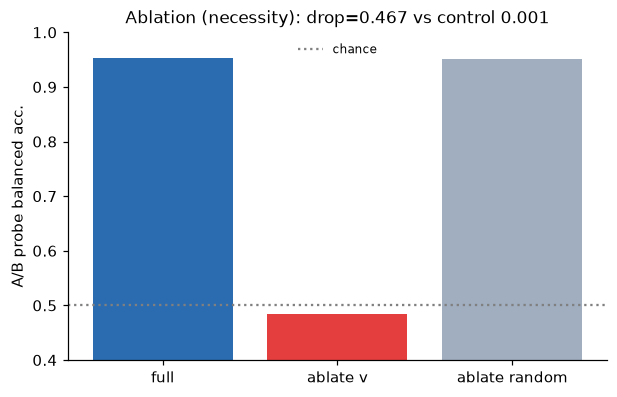

In [8]:
necessity = CA.necessity_test(X_full, cluster_labels, cb_labels, plan,
                              n_splits=cfg.ablation.probe_n_splits, C=cfg.ablation.probe_C,
                              random_state=cfg.random_state)
store.save_json("topol_causal_necessity", necessity)
print(necessity)

fig = V.plot_ablation(necessity)
show_fig(store, "23_causal_necessity", fig)

## 5 - $v_{CB}^t$ magnitude before vs. after

*Script equivalent: `17_causal_ablation_analysis.py` step 2. Saves to:
`tables/topol_causal_cb_magnitude.csv`, `figures/24_causal_cb_magnitude.*`.*

Direct sanity check, not a finding: for topics where $v_{CB}^t$ itself was
one of the ablated directions (marked `*`), $\|v_{CB}^t\|$ recomputed on the
ablated activations should collapse towards 0.

,topic,magnitude_before,magnitude_after
0,0,280.949381,2.640678e-12
1,1,316.829982,3.714412e-12
2,2,308.242330,3.572747e-12
3,3,288.231867,3.466984e-12
4,4,354.297159,2.347042e-12
5,5,246.108708,3.657461e-12
6,6,288.380878,2.496931e-12
7,7,207.635004,1.032628e-11
8,8,226.534959,8.762861e-12
9,9,413.490610,1.376031e-11


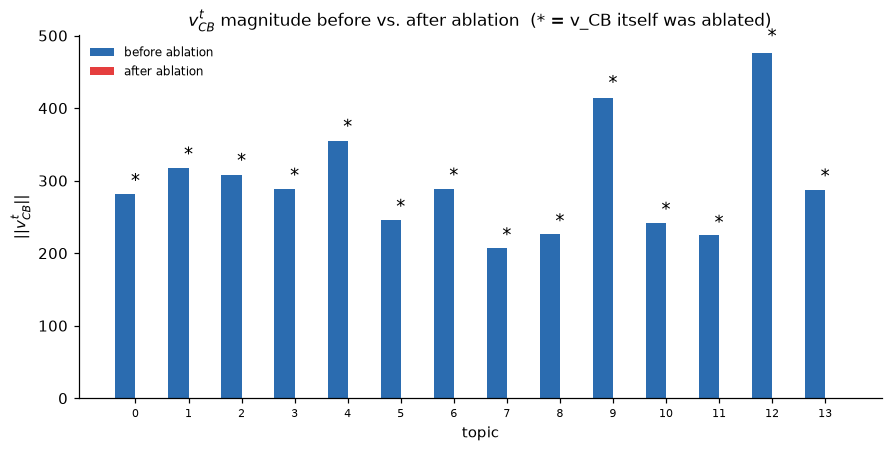

In [9]:
fld_geo = CA.field_geometry_before_after(X_full, X_ablated, cluster_labels, cb_labels)
mag_df = pd.DataFrame({"topic": fld_geo["clusters"],
                       "magnitude_before": fld_geo["magnitude_before"],
                       "magnitude_after": fld_geo["magnitude_after"]})
store.save_table("topol_causal_cb_magnitude", mag_df)
display(mag_df)

ablated_topics = plan_summary.loc[plan_summary["sources"].str.contains("v_CB", na=False), "topic"]
fig = V.plot_cb_magnitude_before_after(mag_df["topic"], mag_df["magnitude_before"],
                                       mag_df["magnitude_after"], ablated_topics=ablated_topics)
show_fig(store, "24_causal_cb_magnitude", fig)

## 6 - Excess axes: does independence hold up?

*Script equivalent: `17_causal_ablation_analysis.py` step 3. Saves to:
`tables/topol_causal_excess_axis_retention.csv`, `figures/25_causal_excess_axis_retention.*`.*

Gate-passing axes that were NOT selected (low RoBERTa `|sentiment_delta|`)
were left alone by ablation -- their discovered DIRECTION is a fixed
vector either way. What CAN change is whether that fixed direction still
discriminates its own pole partition once the sentiment directions are
projected out of the activations it is measured against
(`d_retained_frac` = effect size after / effect size before). Near 1.0 means
the low `cos_to_cb` that spared an axis from selection reflected real
independence; near 0 means it was more entangled with sentiment than that
cosine threshold suggested.

442 excess axes | d_retained_frac: median=0.651  mean=0.654


,topic,contrast_index,d_before,d_after,d_retained_frac
136,4,30,1.192159,0.041834,0.035091
0,0,1,0.819860,0.047421,0.057840
134,4,23,1.265240,0.076425,0.060403
5,0,7,1.309323,0.100050,0.076413
6,0,8,1.566428,0.122083,0.077937
135,4,25,1.060654,0.085147,0.080278
2,0,3,0.703185,0.056458,0.080288
4,0,6,1.239961,0.101346,0.081733
9,0,11,1.882712,0.164739,0.087501
408,12,47,1.114041,0.102166,0.091707


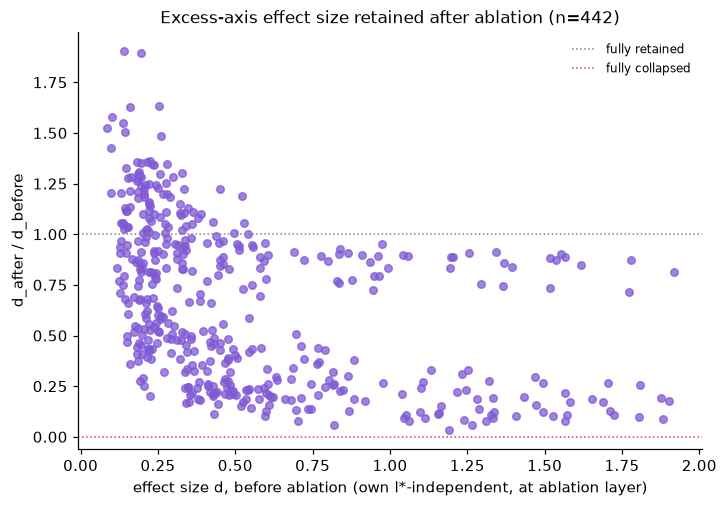

In [10]:
excess_df = CA.excess_axis_effect_size_before_after(
    gate_results, selected_axes, cluster_labels, X_full, X_ablated, LAYER)
store.save_table("topol_causal_excess_axis_retention", excess_df)
print(f"{len(excess_df)} excess axes | d_retained_frac: "
      f"median={excess_df['d_retained_frac'].median():.3f}  mean={excess_df['d_retained_frac'].mean():.3f}")
display(excess_df.sort_values("d_retained_frac").head(10))

fig = V.plot_excess_axis_retention(excess_df)
show_fig(store, "25_causal_excess_axis_retention", fig)

In [14]:
excess_axes = align_df[~align_df["axis_id"].isin(selected_axes["axis_id"])].reset_index(drop=True)
print(f"{len(excess_axes)} excess axes")


442 excess axes


In [15]:
# -- Part 8: did the MEANING survive, not just the effect size? -----------
# Script equivalent: 18_causal_interpretation.py (steps 1-3).
texts = store.load_object("texts")
doc_sentiment = store.load_array("topol_doc_sentiment")
tfidf_summary = pd.read_csv(
    os.path.join(store.dir, store.manifest["entries"]["topol_pv_tfidf_summary"]["path"]))

if have(store, "topol_causal_axis_geometry_after"):
    print("[cache] topol_causal_axis_geometry_after found on disk, loading")
    geo_df = pd.read_csv(
        os.path.join(store.dir, store.manifest["entries"]["topol_causal_axis_geometry_after"]["path"]))
else:
    from topolm import causal_interpretation as CI
    geo_df, labels_after_map = CI.axis_geometry_after(gate_results, cluster_labels, X_ablated, LAYER, excess_axes)
    store.save_table("topol_causal_axis_geometry_after", geo_df)

print(f"cos(direction before,after): median={geo_df['cos_direction_before_after'].median():.3f}")
print(f"ARI(pole membership before,after): median={geo_df['ari_pole_membership'].median():.3f}")
display(geo_df.sort_values("cos_direction_before_after").head(10))


cos(direction before,after): median=0.297
ARI(pole membership before,after): median=0.138


,axis_id,topic,contrast_index,d_before,d_after,d_retained_frac,cos_direction_before_after,ari_pole_membership,n_flipped,n_docs
136,182,4,30,1.192159,0.041834,0.035091,0.018934,0.039235,332,831
0,0,0,1,0.819860,0.047421,0.057840,0.021132,0.049843,498,1285
2,2,0,3,0.703185,0.056458,0.080288,0.028772,0.049143,499,1285
5,6,0,7,1.309323,0.100050,0.076413,0.030817,0.060896,483,1285
4,5,0,6,1.239961,0.101346,0.081733,0.032410,0.064829,478,1285
134,176,4,23,1.265240,0.076425,0.060403,0.033255,0.067071,307,831
6,7,0,8,1.566428,0.122083,0.077937,0.033312,0.061682,482,1285
16,21,0,23,0.429987,0.049022,0.114008,0.039425,0.029363,531,1285
9,10,0,11,1.882712,0.164739,0.087501,0.040163,0.130295,410,1285
135,178,4,25,1.060654,0.085147,0.080278,0.042296,0.123262,269,831


In [17]:
import importlib
from topolm import viz as V
importlib.reload(V)


<module 'topolm.viz' from '/home/users/g/gomeztei/topol_3/scr/topolm/viz.py'>

[cache] topol_causal_tfidf_shift found on disk, loading
Jaccard(vocab before,after): A median=0.176  B median=0.176


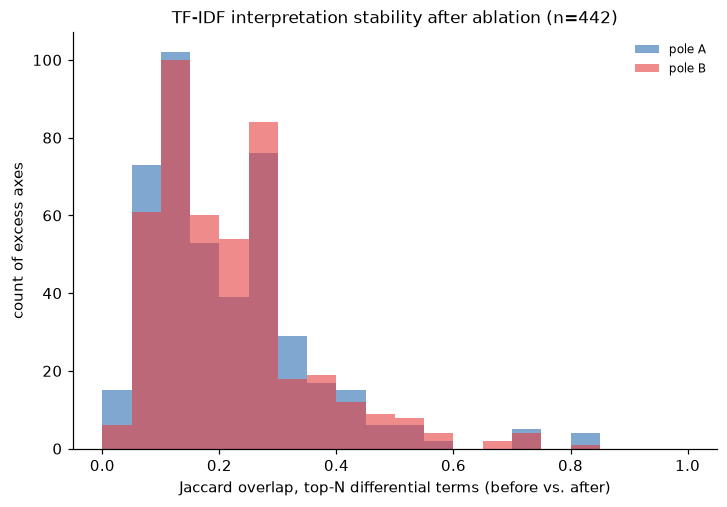

In [18]:
from topolm import causal_interpretation as CI

if have(store, "topol_causal_tfidf_shift"):
    print("[cache] topol_causal_tfidf_shift found on disk, loading")
    tfidf_shift_df = pd.read_csv(
        os.path.join(store.dir, store.manifest["entries"]["topol_causal_tfidf_shift"]["path"]))
else:
    _, labels_after_map = CI.axis_geometry_after(gate_results, cluster_labels, X_ablated, LAYER, excess_axes)
    tfidf_shift_df = CI.tfidf_interpretation_shift(texts, cluster_labels, tfidf_summary, labels_after_map, top_n=20)
    store.save_table("topol_causal_tfidf_shift", tfidf_shift_df)

print(f"Jaccard(vocab before,after): A median={tfidf_shift_df['jaccard_A'].median():.3f}  "
      f"B median={tfidf_shift_df['jaccard_B'].median():.3f}")
fig = V.plot_tfidf_jaccard(tfidf_shift_df)
show_fig(store, "28_causal_tfidf_jaccard", fig)


## 7 - UMAP re-clustering: does topic structure survive?

*Script equivalent: `17_causal_ablation_analysis.py` step 4. Saves to:
`objects/topol_causal_reclustering.json`, `figures/26_causal_umap_before_after.*`,
`figures/27_causal_cluster_agreement.*`.*

Re-runs `manifold.cluster_documents` (the SAME UMAP+Leiden settings Part 2
of `pipeline_2.ipynb` used) on the unablated activations at `LAYER` AND on
the ablated ones -- a FRESH "before" re-clustering, not a reload of Part 2's
saved `coords_2d`/`cluster_labels`, because those were built from a
different pooling convention (full attention mask, vs. this cache's
BOS/special-token-excluded pooling); comparing fresh-before vs. after keeps
the ONLY difference between the two runs being ablation itself. Adjusted
Rand index is the single-number summary: high = topic identity mostly
survives ablation (topic structure was not riding mainly on the ablated
directions); low = much of it was.

**This is the slow step -- two full UMAP+Leiden runs over the whole
corpus, likely several minutes each on CPU.** Set `RUN_UMAP = False` to
skip it.

re-clustering before ablation (fresh UMAP+Leiden on unablated activations)...
re-clustering after ablation...
ARI(before,after)=0.698  n_clusters before=17 after=15
(sanity: ARI(fresh-before, original Part-2 clustering)=0.698 -- expected high but not 1.0, given the pooling-convention difference above)


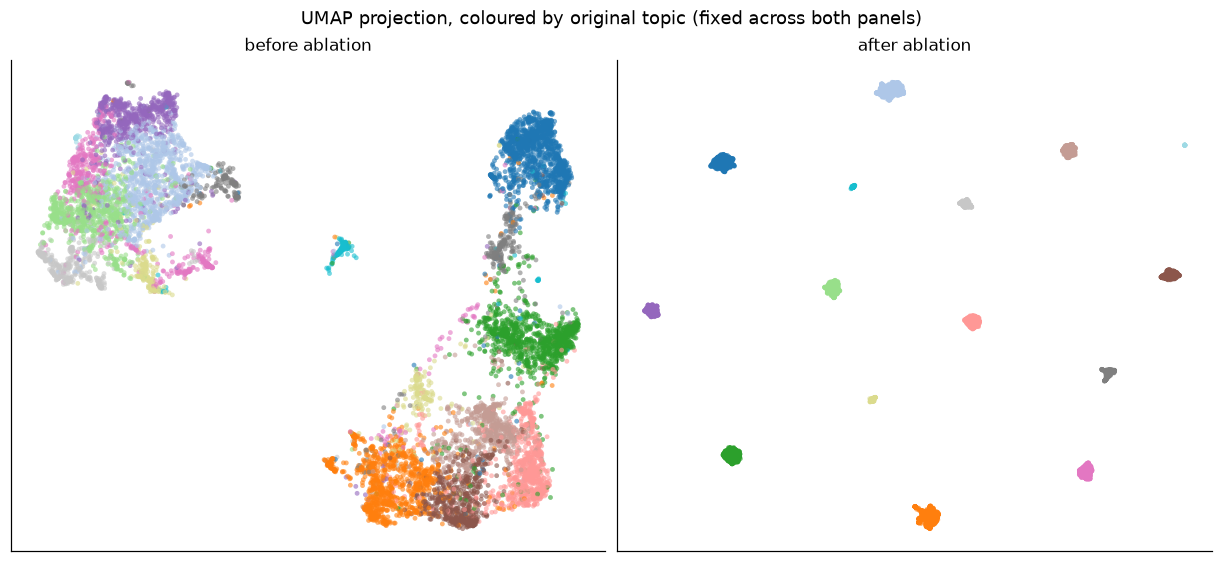

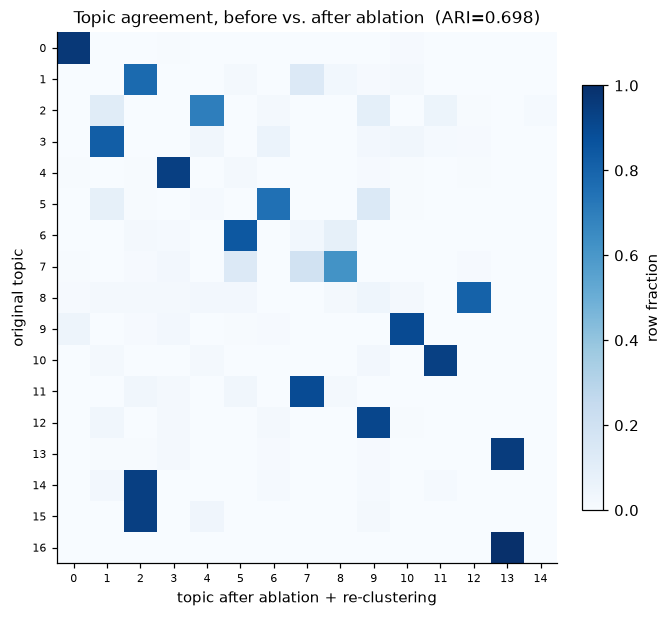

In [11]:
RUN_UMAP = True

if RUN_UMAP:
    from sklearn.metrics import adjusted_rand_score

    print("re-clustering before ablation (fresh UMAP+Leiden on unablated activations)...")
    cl_before = M.cluster_documents(X_full, cfg)
    print("re-clustering after ablation...")
    cl_after = M.cluster_documents(X_ablated, cfg)

    ari = float(adjusted_rand_score(cl_before["labels"], cl_after["labels"]))
    ari_vs_original = float(adjusted_rand_score(cluster_labels, cl_before["labels"]))
    store.save_json("topol_causal_reclustering", {
        "ari_before_vs_after": ari, "ari_fresh_before_vs_original_clustering": ari_vs_original,
        "n_clusters_before": cl_before["n_clusters"], "n_clusters_after": cl_after["n_clusters"],
    })
    print(f"ARI(before,after)={ari:.3f}  n_clusters before={cl_before['n_clusters']} "
          f"after={cl_after['n_clusters']}")
    print(f"(sanity: ARI(fresh-before, original Part-2 clustering)={ari_vs_original:.3f} "
          f"-- expected high but not 1.0, given the pooling-convention difference above)")

    fig = V.plot_umap_before_after(cl_before["coords_2d"], cl_after["coords_2d"], cluster_labels,
                                   label_name="original topic")
    show_fig(store, "26_causal_umap_before_after", fig)
    fig = V.plot_cluster_agreement(cl_before["labels"], cl_after["labels"], ari=ari)
    show_fig(store, "27_causal_cluster_agreement", fig)
else:
    print("RUN_UMAP=False -- skipped")

## 8 - Summary: reading the four results together

* **Necessity** (Part 4): `necessity_drop` well above `control_drop` means
  the ablated directions were load-bearing for the regime split, not just
  an arbitrary same-rank subspace -- the strongest single piece of causal
  evidence in this notebook, since it is the only comparison with a random
  control baked in.
* **$v_{CB}^t$ magnitude** (Part 5) is a sanity check on the ablation
  itself, not a finding: if it does NOT collapse for a `*`-marked topic,
  something upstream (layer mismatch, a sign/normalisation bug) needs
  investigating before trusting anything else here.
* **Excess-axis retention** (Part 6) is the sharpest test of the
  "independent, non-sentiment structure" claim the whole `pipeline_2.ipynb`
  discovery pass is built around: axes with `d_retained_frac` near 1.0 are
  independent of sentiment in a sense stronger than a low cosine to
  $v_{CB}^t$ alone establishes.
* **UMAP re-clustering** (Part 7) is the coarsest, most holistic check --
  whether topic IDENTITY itself (not just any one axis) was riding on
  sentiment.

**Not done here:** re-running axis discovery (`06_topol_discovery.py`'s
recursive bipartition + split-half gate) on `X_ablated` to see whether NEW
structure emerges once sentiment is gone. That is a different, more
expensive question (does removing the dominant direction reveal axes the
original discovery pass's early splits absorbed into it?) and would need
the full per-topic discovery pipeline re-run on the ablated cache, not just
this notebook's cheaper before/after comparisons.

In [12]:
print("run dir:", store.dir)
print()
print("causal-ablation entries in this run:")
for k, kind in sorted(store.list_entries().items()):
    if k.startswith("topol_causal") or k.startswith(("23_causal", "24_causal", "25_causal",
                                                      "26_causal", "27_causal")):
        print(f"  [{kind:9s}] {k}")

run dir: /home/users/g/gomeztei/topol_3/scr/runs/amazon_reviews_pipeline_2

causal-ablation entries in this run:
  [figure   ] 23_causal_necessity
  [figure   ] 24_causal_cb_magnitude
  [figure   ] 25_causal_excess_axis_retention
  [figure   ] 26_causal_umap_before_after
  [figure   ] 27_causal_cluster_agreement
  [array    ] topol_causal_ablated_embedding
  [table    ] topol_causal_cb_magnitude
  [table    ] topol_causal_excess_axis_retention
  [json     ] topol_causal_meta
  [json     ] topol_causal_necessity
  [pickle   ] topol_causal_plan
  [json     ] topol_causal_reclustering
  [table    ] topol_causal_selected_axes
  [table    ] topol_causal_summary


## Part 9 (Ridge R² over the full corpus)

{'acc_full': 0.8239974891853405, 'acc_ablate_direction': -0.1980216755733304, 'acc_ablate_random': 0.8267746227646646, 'necessity_drop': 1.022019164758671, 'control_drop': -0.002777133579324076}


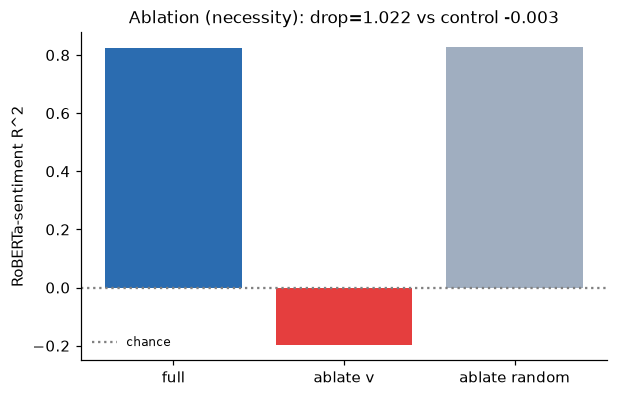

In [19]:
from topolm import causal_interpretation as CI

if have(store, "topol_causal_sentiment_survival"):
    print("[cache] topol_causal_sentiment_survival found on disk, loading")
    survival = store.load_json("topol_causal_sentiment_survival")
else:
    survival = CI.sentiment_survival_test(X_full, X_ablated, doc_sentiment, cluster_labels, plan,
                                          n_splits=cfg.ablation.probe_n_splits, random_state=cfg.random_state)
    store.save_json("topol_causal_sentiment_survival", survival)

print(survival)
fig = V.plot_ablation(survival, metric_label="RoBERTa-sentiment R^2", chance_line=0.0, ylim=None)
show_fig(store, "30_causal_sentiment_survival", fig)


## Part 10 (GPU required — gemma-3-4b-it explanations of the after-ablation split)

In [ ]:
import glob as _glob
from huggingface_hub import snapshot_download
from topolm.config import ModelConfig
from topolm.backends import make_backend
from topolm import pole_llm as PL, causal_interpretation as CI

_, labels_after_map = CI.axis_geometry_after(gate_results, cluster_labels, X_ablated, LAYER, excess_axes)
data_after, tfidf_summary_after = CI.build_after_ablation_axis_dataset(
    cluster_labels, texts, labels_after_map, tfidf_shift_df)

axis_index_after = tfidf_shift_df.rename(columns={"axis_id": "axis_id"})[["axis_id", "topic"]].copy()
axis_index_after["contrast_index"] = 0   # explain_axes_it only needs axis_id/topic to key its output

IT_MODEL = "google/gemma-3-4b-it"
hf_cache_dir = os.path.expanduser("~/scratch/hf_cache")
it_snapshot = _glob.glob(os.path.join(hf_cache_dir, "models--" + IT_MODEL.replace("/", "--"), "snapshots", "*"))
it_snapshot = it_snapshot[0] if it_snapshot else snapshot_download(repo_id=IT_MODEL, cache_dir=hf_cache_dir)

it_cfg = Config.from_dict(store.load_json("config"))
it_cfg.model = ModelConfig(name=it_snapshot, layer=it_cfg.model.layer, pooling=it_cfg.model.pooling,
                           dtype=it_cfg.model.dtype, device=it_cfg.model.device,
                           max_length=it_cfg.model.max_length, batch_size=it_cfg.model.batch_size)
backend_it = make_backend(it_cfg)

explanations_after = PL.explain_axes_it(backend_it, data_after, axis_index_after,
                                        tfidf_summary=tfidf_summary_after,
                                        n_snippets=4, max_new_tokens=80, batch_size=4,
                                        random_state=cfg.random_state)
store.save_table("topol_causal_llm_explanations_after", explanations_after)
display(explanations_after.head(10))
